<a href="https://colab.research.google.com/github/dicp24-cmyk/analisis-de-ventas/blob/main/analisis_ventas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de ventas con pandas

Resolución de los 12 ejercicios de la hoja **Ejercicios** del archivo `practica_analisis_datos_empresariales.xlsx`.

**Contexto:** TecnoAndes vende productos de tecnología, oficina y software en 4 regiones. Los datos (ficticios) van de enero 2025 a octubre 2026 y los montos están en USD.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.options.display.float_format = "{:,.2f}".format

# El notebook busca el Excel en la carpeta actual o en la carpeta superior (repositorio)
nombre = "practica_analisis_datos_empresariales.xlsx"
ruta = next(p for p in (Path(nombre), Path("..") / nombre) if p.exists())
df = pd.read_excel(ruta, sheet_name="Ventas")
df.head()

,Fecha,Región,Vendedor,Producto,Categoría,Unidades,Precio unitario (USD),Descuento,Costo unitario (USD),Ingreso (USD),Costo total (USD),Margen (USD),Margen %
0,2025-01-06,Norte,Tomás Araya,Licencia CRM,Software,35,900,0.05,500,"29,925.00",17500,"12,425.00",0.42
1,2025-01-13,Sur,Diego Fuentes,Licencia CRM,Software,15,900,0.00,500,"13,500.00",7500,"6,000.00",0.44
2,2025-01-13,Sur,Matías Vega,"Monitor 27""",Tecnología,16,350,0.05,260,"5,320.00",4160,"1,160.00",0.22
3,2025-01-27,Austral,Valentina Soto,Laptop Pro,Tecnología,3,1200,0.00,900,"3,600.00",2700,900.00,0.25
4,2025-01-30,Austral,Javiera Núñez,Laptop Pro,Tecnología,34,1200,0.00,900,"40,800.00",30600,"10,200.00",0.25


## 1. Revisión y limpieza

In [17]:
df.info()
print("Nulos por columna:\n", df.isna().sum())
print("Filas duplicadas:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Fecha                  150 non-null    datetime64[ns]
 1   Región                 150 non-null    object        
 2   Vendedor               150 non-null    object        
 3   Producto               150 non-null    object        
 4   Categoría              150 non-null    object        
 5   Unidades               150 non-null    int64         
 6   Precio unitario (USD)  150 non-null    int64         
 7   Descuento              150 non-null    float64       
 8   Costo unitario (USD)   150 non-null    int64         
 9   Ingreso (USD)          150 non-null    float64       
 10  Costo total (USD)      150 non-null    int64         
 11  Margen (USD)           150 non-null    float64       
 12  Margen %               150 non-null    float64       
dtypes: da

In [18]:
# Nombres de columnas más cómodos para programar
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"\s*\(usd\)", "", regex=True)
              .str.replace(" ", "_"))

df = df.drop_duplicates()
df["fecha"] = pd.to_datetime(df["fecha"], errors="coerce")
for col in ["región", "vendedor", "producto", "categoría"]:
    df[col] = df[col].str.strip()
df = df.dropna(subset=["fecha", "unidades"])

# Las columnas calculadas llegan desde Excel; las recalculamos para no depender de ellas
df["ingreso"] = df["unidades"] * df["precio_unitario"] * (1 - df["descuento"])
df["costo_total"] = df["unidades"] * df["costo_unitario"]
df["margen"] = df["ingreso"] - df["costo_total"]
df["margen_pct"] = df["margen"] / df["ingreso"]

print(df.shape)
df.columns.tolist()

(150, 14)


['fecha',
 'región',
 'vendedor',
 'producto',
 'categoría',
 'unidades',
 'precio_unitario',
 'descuento',
 'costo_unitario',
 'ingreso',
 'costo_total',
 'margen',
 'margen_%',
 'margen_pct']

## Ejercicio 1. Ingreso total del período

In [19]:
ingreso_total = df["ingreso"].sum()
print(f"Ingreso total: USD {ingreso_total:,.0f}")

Ingreso total: USD 1,902,425


## Ejercicio 2. Margen % total

Se calcula como margen total / ingreso total. No se promedia la columna `margen_pct`, porque eso daría el mismo peso a ventas grandes y pequeñas.

In [20]:
margen_total = df["margen"].sum()
print(f"Margen total: USD {margen_total:,.0f}")
print(f"Margen %: {margen_total / ingreso_total:.1%}")

Margen total: USD 440,735
Margen %: 23.2%


## Ejercicio 3. Región con mayor ingreso

In [21]:
por_region = df.groupby("región")["ingreso"].sum().sort_values(ascending=False)
print(por_region)
print("\nMayor ingreso:", por_region.idxmax())

región
Sur       633,974.50
Austral   431,936.50
Centro    418,896.50
Norte     417,617.50
Name: ingreso, dtype: float64

Mayor ingreso: Sur


## Ejercicio 4. Ventas con margen negativo

In [22]:
negativas = df[df["margen"] < 0]
print("Ventas con margen negativo:", len(negativas))
negativas[["fecha", "producto", "descuento", "ingreso", "margen"]]

Ventas con margen negativo: 6


,fecha,producto,descuento,ingreso,margen
8,2025-02-13,"Monitor 27""",0.30,"6,615.00",-405.00
12,2025-03-17,Laptop Pro,0.30,"26,040.00","-1,860.00"
19,2025-05-01,Escritorio Regulable,0.30,"5,040.00",-240.00
34,2025-07-13,Escritorio Regulable,0.30,"5,040.00",-240.00
82,2026-03-19,Escritorio Regulable,0.30,"10,395.00",-495.00
86,2026-03-31,Escritorio Regulable,0.30,"3,780.00",-180.00


## Ejercicio 5. Producto con más unidades vendidas

In [23]:
por_producto = df.groupby("producto")["unidades"].sum().sort_values(ascending=False)
print(por_producto)
print("\nMás vendido:", por_producto.idxmax())

producto
Laptop Pro              718
Silla Ergonómica        556
Escritorio Regulable    517
Licencia CRM            507
Software Contable       500
Monitor 27"             443
Name: unidades, dtype: int64

Más vendido: Laptop Pro


## Ejercicio 6. Vendedor con mayor margen (USD)

In [24]:
por_vendedor = df.groupby("vendedor")["margen"].sum().sort_values(ascending=False)
print(por_vendedor)
print("\nMayor margen:", por_vendedor.idxmax())

vendedor
Tomás Araya      98,369.00
Javiera Núñez    90,270.50
Matías Vega      71,936.00
Valentina Soto   65,232.50
Diego Fuentes    60,806.00
Camila Rojas     54,121.00
Name: margen, dtype: float64

Mayor margen: Tomás Araya


## Ejercicio 7. Ingreso del tercer trimestre de 2026

In [25]:
q3 = df[(df["fecha"] >= "2026-07-01") & (df["fecha"] <= "2026-09-30")]
print(f"Ingreso Q3 2026: USD {q3['ingreso'].sum():,.0f}")

Ingreso Q3 2026: USD 383,664


## Ejercicio 8. Descuento promedio (solo ventas con descuento)

In [26]:
con_desc = df[df["descuento"] > 0]
print(f"Descuento promedio: {con_desc['descuento'].mean():.1%}")
print("Ventas con descuento:", len(con_desc), "de", len(df))

Descuento promedio: 17.8%
Ventas con descuento: 94 de 150


## Ejercicio 9. Categoría con mayor margen %

In [27]:
cat = df.groupby("categoría")[["margen", "ingreso"]].sum()
cat["margen_pct"] = cat["margen"] / cat["ingreso"]
print(cat.sort_values("margen_pct", ascending=False))
print("\nMayor margen %:", cat["margen_pct"].idxmax())

               margen    ingreso  margen_pct
categoría                                   
Software   235,845.00 654,345.00        0.36
Oficina     63,515.00 345,325.00        0.18
Tecnología 141,375.00 902,755.00        0.16

Mayor margen %: Software


## Ejercicio 10. Crecimiento enero–octubre 2026 vs. 2025

In [28]:
def ingreso_periodo(anio):
    m = (df["fecha"] >= f"{anio}-01-01") & (df["fecha"] <= f"{anio}-10-31")
    return df.loc[m, "ingreso"].sum()

i25, i26 = ingreso_periodo(2025), ingreso_periodo(2026)
print(f"Ene–oct 2025: USD {i25:,.0f}")
print(f"Ene–oct 2026: USD {i26:,.0f}")
print(f"Crecimiento: {i26 / i25 - 1:.1%}")

Ene–oct 2025: USD 795,818
Ene–oct 2026: USD 1,106,607
Crecimiento: 39.1%


## Ejercicio 11. Ingresos por mes

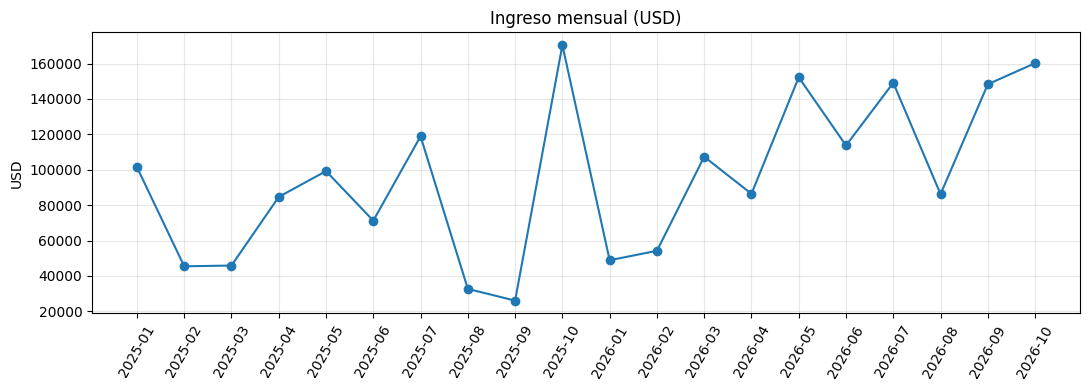

In [29]:
mensual = df.groupby(df["fecha"].dt.to_period("M"))["ingreso"].sum()
mensual.index = mensual.index.astype(str)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mensual.index, mensual.values, marker="o")
ax.set_title("Ingreso mensual (USD)")
ax.set_ylabel("USD")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Tendencia observada:** el ingreso mensual muestra una tendencia al alza: el promedio pasó de unos USD 75.000 en 2025 a unos USD 125.000 en 2026. Aun así, la serie es muy volátil, con picos y caídas bruscas entre meses consecutivos. Además, no hay datos de noviembre y diciembre de 2025, por lo que la línea une octubre de 2025 con enero de 2026.

## Ejercicio 12. Recomendación para la gerencia

Apóyate en los resultados anteriores. Este gráfico y esta tabla muestran cómo el descuento afecta el margen.

               margen    ingreso  margen_pct
tramo_desc                                  
0%         222,240.00 731,890.00        0.30
1–10%       97,526.00 364,386.00        0.27
11–20%      95,574.00 456,514.00        0.21
21–30%      25,395.00 349,635.00        0.07


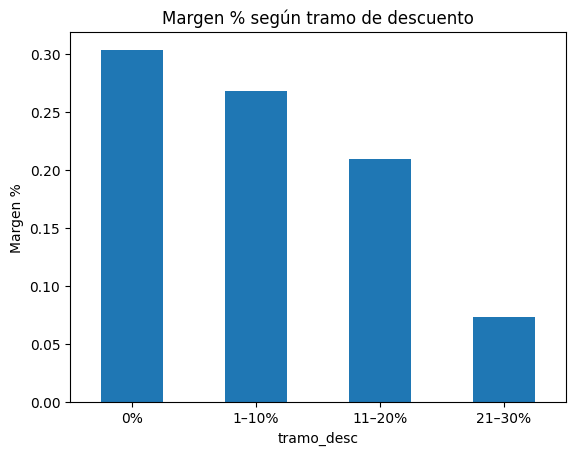

In [30]:
df["tramo_desc"] = pd.cut(df["descuento"], [-0.01, 0, 0.10, 0.20, 0.30],
                          labels=["0%", "1–10%", "11–20%", "21–30%"])
efecto = df.groupby("tramo_desc", observed=True)[["margen", "ingreso"]].sum()
efecto["margen_pct"] = efecto["margen"] / efecto["ingreso"]
print(efecto)

efecto["margen_pct"].plot(kind="bar", title="Margen % según tramo de descuento", rot=0)
plt.ylabel("Margen %")
plt.show()

**Recomendación:** *(escribe aquí 2–3 líneas: por ejemplo, si conviene limitar descuentos altos en ciertos productos o categorías)*

## Guardar resultados

In [31]:
Path("../output").mkdir(exist_ok=True)
df.to_csv("../output/ventas_limpias.csv", index=False)
print("Guardado: output/ventas_limpias.csv")

Guardado: output/ventas_limpias.csv
